In [1]:
%load_ext watermark
%watermark

Last updated: 2022-08-30T23:05:39.357413-05:00

Python implementation: CPython
Python version       : 3.7.4
IPython version      : 7.8.0

Compiler    : MSC v.1915 64 bit (AMD64)
OS          : Windows
Release     : 10
Machine     : AMD64
Processor   : Intel64 Family 6 Model 158 Stepping 9, GenuineIntel
CPU cores   : 8
Architecture: 64bit



In [2]:
import pandas as pd
%matplotlib inline 
# no crea widget ni nada para no presentar resultados.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.figsize'] = (12,12) # 10 pulgadas de ancho y 10 de alto para todos los plots


In D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test.mplstyle: 
The text.latex.preview rcparam was deprecated in Matplotlib 3.3 and will be removed two minor releases later.
In D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test.mplstyle: 
The mathtext.fallback_to_cm rcparam was deprecated in Matplotlib 3.3 and will be removed two minor releases later.
In D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test.mplstyle: Support for setting the 'mathtext.fallback_to_cm' rcParam is deprecated since 3.3 and will be removed two minor releases later; use 'mathtext.fallback : 'cm' instead.
In D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\matplotlib\mpl-data\stylelib\_classic_test.mplstyle: 
The validate_bool_maybe_none function was deprecated in Matplotlib 3.3 and will be removed two minor releases later.
In D:\ProgramData\Anaconda3\

In [7]:
bank_dp = pd.read_csv("../data/bank.csv",sep=',')

In [8]:
bank_dp.shape

(11162, 17)

In [9]:
bank_dp.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


# Análisis exploratorio de datos (EDA): Pre fase

In [10]:
pandas_profiling.ProfileReport(bank_dp)

NameError: name 'pandas_profiling' is not defined

## 1) Objetivo de análisis

Comprender e identificar las principales características que afectan al éxito de que un cliente se suscriba al depósito a plazo fijo

## 2) Identificar entidades

Se agrupan variables del dataset que tienen similar concepto de datos o entidades.

* Cliente info: Relación de productos y saldos que tiene el cliente en el banco
* Contactabilidad: Métricas de contacto usadas en campañas de telemarketing
* Social: información social de la persona

In [18]:
#renombrar columnas
bank_dp = bank_dp.rename(columns = {
 'age':'edad',
 'job':'trabajo',
 'marital':'estadoCivil',
 'education':'educacion',
 'default':'flag_mora',
 'balance':'prom_saldoAnual',
 'housing':'flag_hipotecario',
 'loan':'flag_prestamo',
 'contact':'tipo_contacto',
 'month':'mes_UltContacto',
 'day':'dia_UltContacto',
 'duration':'seg_UltContacto',
 'campaign':'cant_contactoCampanha',
 'pdays':'cantDias_AfterUltContacto',
 'previous':'cant_contactoBeforeCampanha',
 'poutcome':'result_campanha',
 'deposit':'FlagTarget_DP',})

In [19]:
bank_dp.head()

,edad,trabajo,estadoCivil,educacion,flag_mora,prom_saldoAnual,flag_hipotecario,flag_prestamo,tipo_contacto,dia_UltContacto,mes_UltContacto,seg_UltContacto,cant_contactoCampanha,cantDias_AfterUltContacto,cant_contactoBeforeCampanha,result_campanha,FlagTarget_DP
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


Tipos de datos del data set

In [20]:
bank_dp.dtypes

edad                            int64
trabajo                        object
estadoCivil                    object
educacion                      object
flag_mora                      object
prom_saldoAnual                 int64
flag_hipotecario               object
flag_prestamo                  object
tipo_contacto                  object
dia_UltContacto                 int64
mes_UltContacto                object
seg_UltContacto                 int64
cant_contactoCampanha           int64
cantDias_AfterUltContacto       int64
cant_contactoBeforeCampanha     int64
result_campanha                object
FlagTarget_DP                  object
dtype: object

## 3) Calidad de los datos


### Duplicados
No existen registros duplicados para este dataset

In [21]:
#los que se van a eliminar
bank_dp[bank_dp.duplicated()].shape[0]

0

In [22]:
def valores_duplicados_col(df):
    n_records = len(df)
    for columna in df:
        n_por_valor = df[columna].value_counts()
        mas_comun = n_por_valor.iloc[0]
        menos_comun = n_por_valor.iloc[-1]
        print("{} | ValorAlto: {} - ValorBajo:{} | {}".format(
            df[columna].name,
            round(mas_comun/(1.0*n_records),3),
            round(menos_comun / (1.0*n_records),3),
            df[columna].dtype))


Verificar campos duplicados por columnas

In [23]:
valores_duplicados_col(bank_dp)

edad | ValorAlto: 0.044 - ValorBajo:0.0 | int64
trabajo | ValorAlto: 0.23 - ValorBajo:0.006 | object
estadoCivil | ValorAlto: 0.569 - ValorBajo:0.116 | object
educacion | ValorAlto: 0.491 - ValorBajo:0.045 | object
flag_mora | ValorAlto: 0.985 - ValorBajo:0.015 | object
prom_saldoAnual | ValorAlto: 0.069 - ValorBajo:0.0 | int64
flag_hipotecario | ValorAlto: 0.527 - ValorBajo:0.473 | object
flag_prestamo | ValorAlto: 0.869 - ValorBajo:0.131 | object
tipo_contacto | ValorAlto: 0.72 - ValorBajo:0.069 | object
dia_UltContacto | ValorAlto: 0.051 - ValorBajo:0.011 | int64
mes_UltContacto | ValorAlto: 0.253 - ValorBajo:0.01 | object
seg_UltContacto | ValorAlto: 0.003 - ValorBajo:0.0 | int64
cant_contactoCampanha | ValorAlto: 0.43 - ValorBajo:0.0 | int64
cantDias_AfterUltContacto | ValorAlto: 0.746 - ValorBajo:0.0 | int64
cant_contactoBeforeCampanha | ValorAlto: 0.746 - ValorBajo:0.0 | int64
result_campanha | ValorAlto: 0.746 - ValorBajo:0.048 | object
FlagTarget_DP | ValorAlto: 0.526 - ValorB

Vemos que los campos `estadoCivil, educacion, result_campanha,FlagTarget_DP  y tipo_contacto` pueden tener un problema de valores duplicados por campo.

Más del 60% son casados "married" en el data set, tiene sentido de negocio

### Distribución de características en valores categóricos


In [24]:
categorical_features=[feature for feature in bank_dp.columns if ((bank_dp[feature].dtypes=='O') & (feature not in ['FlagTarget_DP']))]
categorical_features

['trabajo',
 'estadoCivil',
 'educacion',
 'flag_mora',
 'flag_hipotecario',
 'flag_prestamo',
 'tipo_contacto',
 'mes_UltContacto',
 'result_campanha']

In [25]:
# Esta no va en tesis , es informativa noma
for col in bank_dp.select_dtypes(include='object').columns:
    print(col)
    print(bank_dp[col].unique())

trabajo
['admin.' 'technician' 'services' 'management' 'retired' 'blue-collar'
 'unemployed' 'entrepreneur' 'housemaid' 'unknown' 'self-employed'
 'student']
estadoCivil
['married' 'single' 'divorced']
educacion
['secondary' 'tertiary' 'primary' 'unknown']
flag_mora
['no' 'yes']
flag_hipotecario
['yes' 'no']
flag_prestamo
['no' 'yes']
tipo_contacto
['unknown' 'cellular' 'telephone']
mes_UltContacto
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'jan' 'feb' 'mar' 'apr' 'sep']
result_campanha
['unknown' 'other' 'failure' 'success']
FlagTarget_DP
['yes' 'no']


In [26]:
for feature in categorical_features:
    print('El feature es `{}` y tiene {} categorias'.format(feature,len(bank_dp[feature].unique())))

El feature es `trabajo` y tiene 12 categorias
El feature es `estadoCivil` y tiene 3 categorias
El feature es `educacion` y tiene 4 categorias
El feature es `flag_mora` y tiene 2 categorias
El feature es `flag_hipotecario` y tiene 2 categorias
El feature es `flag_prestamo` y tiene 2 categorias
El feature es `tipo_contacto` y tiene 3 categorias
El feature es `mes_UltContacto` y tiene 12 categorias
El feature es `result_campanha` y tiene 4 categorias


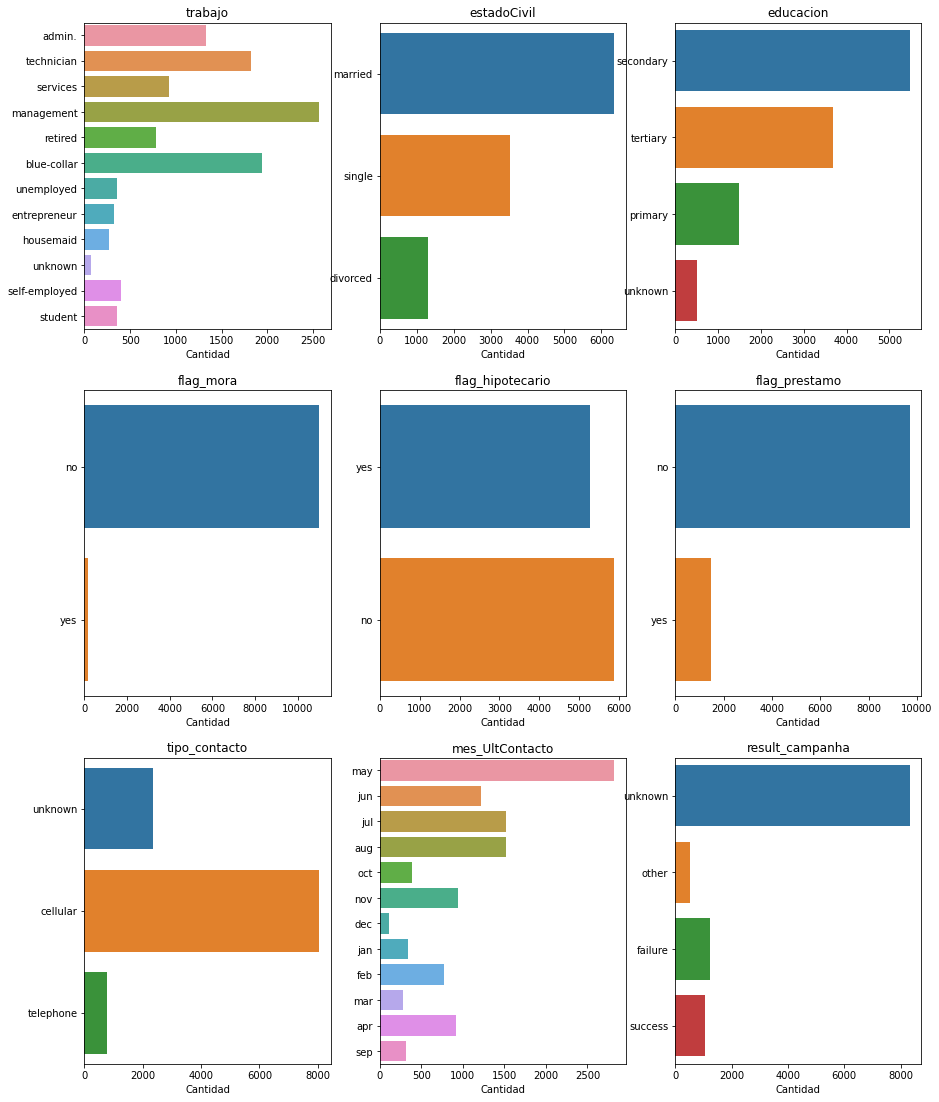

In [27]:
#check count based on categorical features
plt.figure(figsize=(15,80), facecolor='white')
plotnumber =1
for categorical_feature in categorical_features:
    ax = plt.subplot(12,3,plotnumber)
    sns.countplot(y=categorical_feature,data=bank_dp)
    plt.ylabel("")
    plt.xlabel("Cantidad")
    plt.title(categorical_feature)
    plotnumber+=1
plt.show()

In [28]:
#NO VA TESIS
bank_dp.estadoCivil.value_counts(normalize=True)

married     0.568984
single      0.315176
divorced    0.115839
Name: estadoCivil, dtype: float64

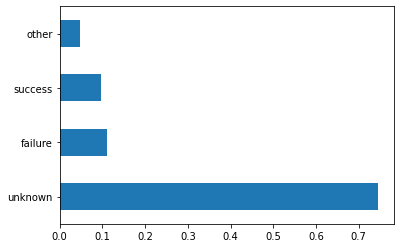

In [30]:
#NO VA TESIS
bank_dp.result_campanha.value_counts(normalize=True).plot.barh();

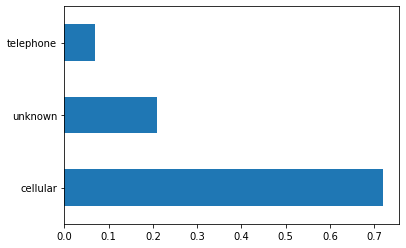

In [31]:
#NO VA TESIS
bank_dp.tipo_contacto.value_counts(normalize=True).plot.barh();

**Conclusiones**:

- Hay 9 características categóricas
- Las características `trabajo` y `mes_UltContacto` son las categorías más altas
- Clientes con cargo de Managers son altos en el conjunto de datos dado y los de rango operativo son con menor proporción.
- Los clientes que se casaron tienen muchos registros en el conjunto de datos dado que los divociados.
- Los clientes cuya formación académica es secundaria se encuentran en gran número en un conjunto de datos determinado
- Los datos del `mes_UltContacto` en el mes de mayo son altos y menos en diciembre
- Más del 20% de los tipo de contacto que tiene el banco con el cliente, es desconocido a tomar en cuentan las posteriores fases.


### Distribución de características en valores numéricos

In [32]:
#NO VA TESIS
# list of numerical variables
numerical_features = [feature for feature in bank_dp.columns if ((bank_dp[feature].dtypes != 'O') & (feature not in ['FlagTarget_DP']))]
print('Variables numéricas: ', len(numerical_features))

# visualise the numerical variables
bank_dp[numerical_features].head()

Variables numéricas:  7


,edad,prom_saldoAnual,dia_UltContacto,seg_UltContacto,cant_contactoCampanha,cantDias_AfterUltContacto,cant_contactoBeforeCampanha
0,59,2343,5,1042,1,-1,0
1,56,45,5,1467,1,-1,0
2,41,1270,5,1389,1,-1,0
3,55,2476,5,579,1,-1,0
4,54,184,5,673,2,-1,0


In [33]:
#NO VA TESIS
discrete_feature=[feature for feature in numerical_features if len(bank_dp[feature].unique())<25]
print("Discrete Variables Count: {}".format(len(discrete_feature)))

Discrete Variables Count: 0


In [34]:
#NO VA TESIS
continuous_features=[feature for feature in numerical_features if feature not in discrete_feature+['FlagTarget_DP']]
print("Continuous feature Count {}".format(len(continuous_features)))

Continuous feature Count 7


Ahora veamos los valores de las columnas numéricas. La forma más conveniente de ver los valores numéricos es trazando histogramas.

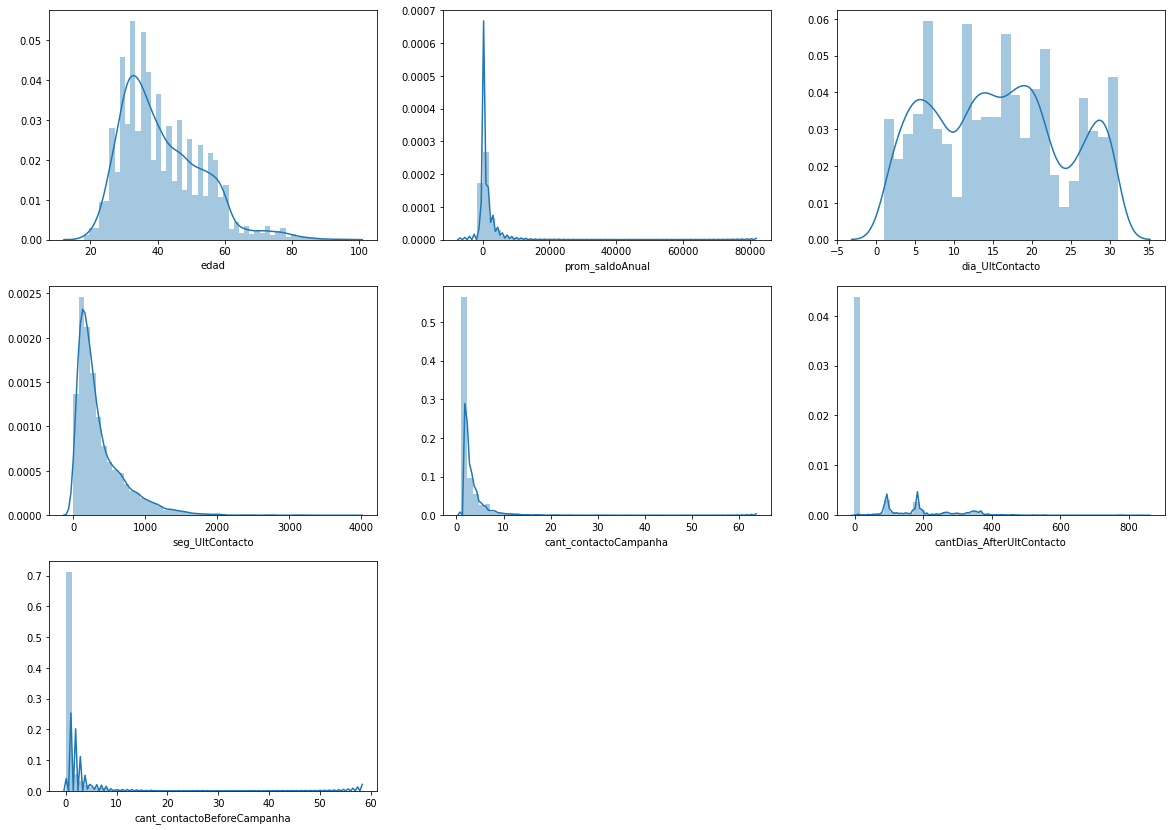

In [35]:
#plot a univariate distribution of continues observations
plt.figure(figsize=(20,60), facecolor='white')
plotnumber =1
for continuous_feature in continuous_features:
    ax = plt.subplot(12,3,plotnumber)
    sns.distplot(bank_dp[continuous_feature])
    plt.xlabel(continuous_feature)
    plotnumber+=1
plt.show()

IndexError: index 2 is out of bounds for axis 0 with size 2

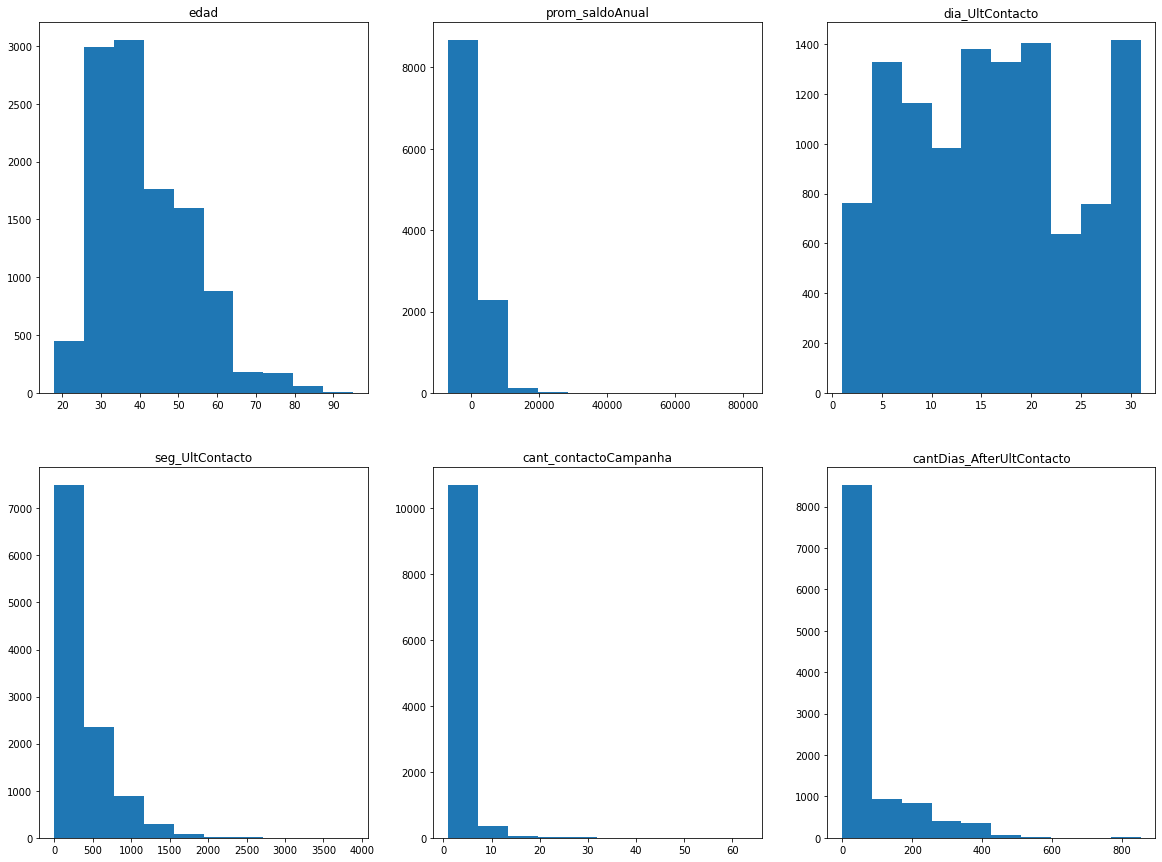

In [36]:
%matplotlib inline 
fig, axs = plt.subplots(2, 3, sharex=False, sharey=False, figsize=(20, 15))

counter = 0
for num_column in numerical_features:
    trace_x = counter // 3
    trace_y = counter % 3
    axs[trace_x, trace_y].hist(bank_dp[num_column])
    axs[trace_x, trace_y].set_title(num_column)
    counter += 1

plt.show()

**Conclusiones**:

- Hay 7 valores numéricos.
- Podemos ver que las columnas numéricas tienen valores atípicos.Posiblemente haya valores incorrectos (datos ruidosos), por lo que debemos mirar más de cerca los datos y decidir cómo manejamos el ruido.
- La `edad` y `dia_UltContacto` siguen una distribución normal
- `prom_saldoAnual`, `seg_UltContacto`, `cant_contactoCampanha`, `cantDias_AfterUltContacto` y `cant_contactoBeforeCampanha` se inclinaron mucho hacia la izquierda, al parecer tienen algunos valores atípicos.

### Medidas de tendencia central en valores numéricos

In [37]:
summary_stats = round(bank_dp.describe().T,2)
summary_stats.drop(['count'], axis=1, inplace=True)
#se va a los cuartiles
summary_stats.rename (columns={'mean':'Media', 'std': 'Desviacion Standard', 'min': 'Minimo', \
                               '25%':'Q1', '50%': 'Mediana', '75%':'Q3', 'max':'Maximo'}, inplace=True)
summary_stats


,Media,Desviacion Standard,Minimo,Q1,Mediana,Q3,Maximo
edad,41.23,11.91,18.0,32.0,39.0,49.00,95.0
prom_saldoAnual,1528.54,3225.41,-6847.0,122.0,550.0,1708.00,81204.0
dia_UltContacto,15.66,8.42,1.0,8.0,15.0,22.00,31.0
seg_UltContacto,371.99,347.13,2.0,138.0,255.0,496.00,3881.0
cant_contactoCampanha,2.51,2.72,1.0,1.0,2.0,3.00,63.0
cantDias_AfterUltContacto,51.33,108.76,-1.0,-1.0,-1.0,20.75,854.0
cant_contactoBeforeCampanha,0.83,2.29,0.0,0.0,0.0,1.00,58.0


**Conclusiones**:

- La edad Máx es de 95 años y con una media de 41 años
- El `prom_saldoAnual` = saldo medio cuenta con valores negativos como -6 847
- El saldo promedio es de 1528.54 y una deviación estándar que es 3225.41 lo que indica que es muy alta.
- Existen personas que se las ha contactado 63 veces como máximo por campaña.
- En promedio 371.99 segundos se toma el área de telemarketing para contar al cliente sobre la campaña.
- `cantDias_AfterUltContacto` Cantidad de días luego del último contacto tiene valor negativo, quiere decir que el cliente no  fue previamente contactado
- En promedio 1 vez se le ha contactado al cliente antes de que entre a esta nueva campaña.



### Valores con un solo valor
No existen, todos tienen por lo menos 2 valores distintos por columna

In [12]:
for column in bank_dp.columns:
    print(column,bank_dp[column].nunique())

edad 77
trabajo 12
estadoCivil 3
educacion 4
flag_mora 2
prom_saldoAnual 7168
flag_hipotecario 2
flag_prestamo 2
tipo_contacto 3
dia_UltContacto 31
mes_UltContacto 12
seg_UltContacto 1573
cant_contactoCampanha 48
cantDias_AfterUltContacto 559
cant_contactoBeforeCampanha 41
result_campanha 4
FlagTarget_DP 2


### Valores inexistentes
No existen valores inexistentes (NA) en el dataset, representado gráficamente a continuación

<AxesSubplot:>

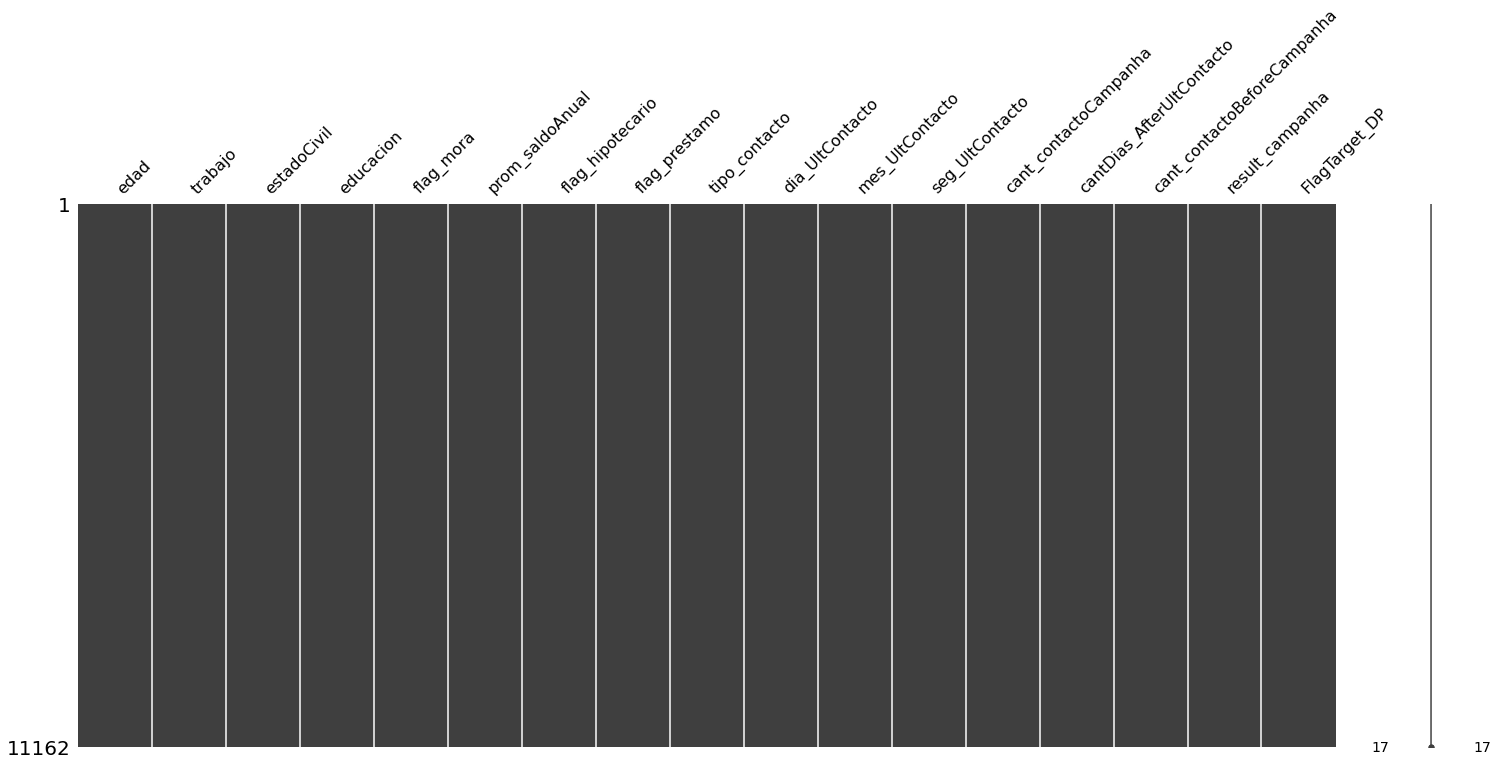

In [38]:
import missingno as msno
msno.matrix(bank_dp)

In [39]:
bank_dp.isnull().sum()

edad                           0
trabajo                        0
estadoCivil                    0
educacion                      0
flag_mora                      0
prom_saldoAnual                0
flag_hipotecario               0
flag_prestamo                  0
tipo_contacto                  0
dia_UltContacto                0
mes_UltContacto                0
seg_UltContacto                0
cant_contactoCampanha          0
cantDias_AfterUltContacto      0
cant_contactoBeforeCampanha    0
result_campanha                0
FlagTarget_DP                  0
dtype: int64

### Valores Extremos (outliers)
Para detectar valores extremos una medida general es considerar outliers aquellos valores con una puntuación Z (z score) mayor de 3, esto es, que se alejan 3 veces o mas desviaciones standard de la media.

El z score se define como:

$$z(x)= \frac{x-\mu}{\sigma}$$

La manera visual de ver los outliers es a través de los gráficos Box Plot, para valores que están muy distintos de la distribución normal

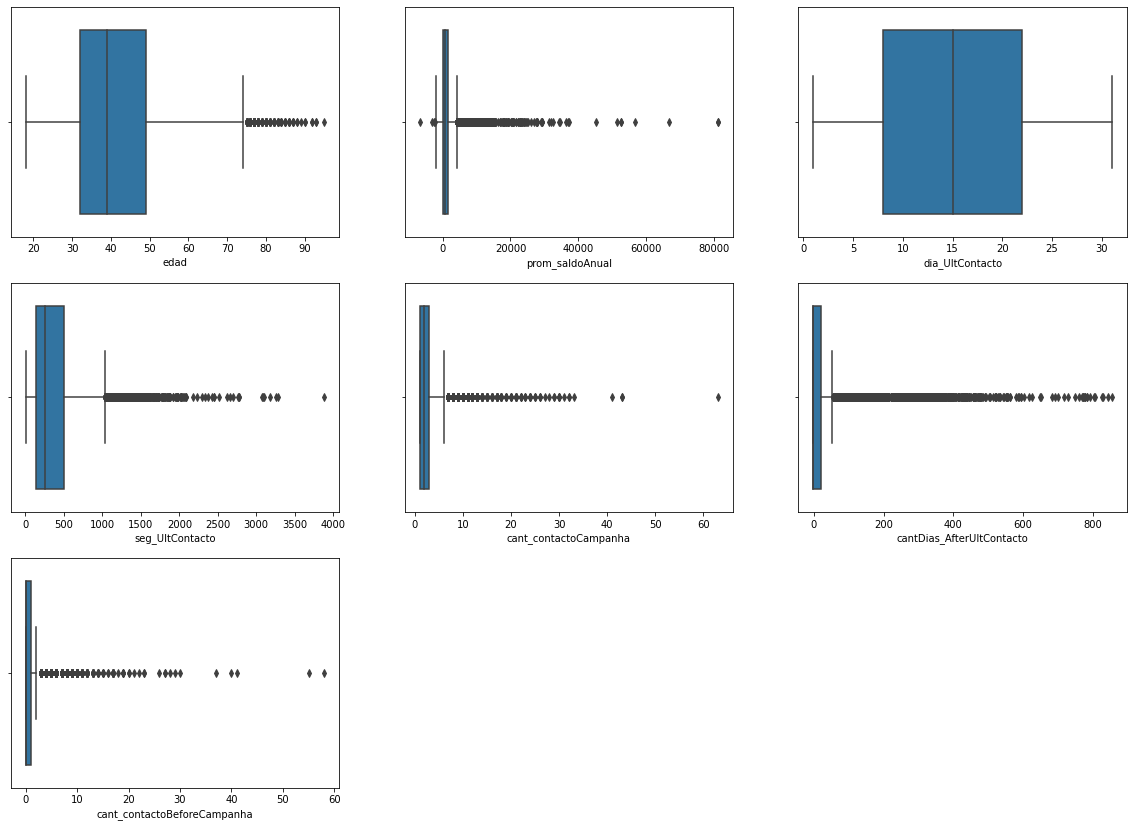

In [40]:
#boxplot on numerical features to find outliers
plt.figure(figsize=(20,60), facecolor='white')
plotnumber =1
for numerical_feature in numerical_features:
    ax = plt.subplot(12,3,plotnumber)
    sns.boxplot(bank_dp[numerical_feature])
    plt.xlabel(numerical_feature)
    plotnumber+=1
plt.show()

In [44]:
#falta agregar el valor de z por el cual se hacen outliers
from scipy import stats
import numpy as np

def outliers_col(df):
    for columna in df:
        if df[columna].dtype != np.object:
            # valida q sean numericos
            n_outlier = len(df[np.abs(stats.zscore(df[columna]))>3])
            if (n_outlier>0):
                print("{} | {} registros con Z > 3 | {}".format(
                    df[columna].name,n_outlier,
                    df[columna].dtype
                ))

In [46]:
outliers_col(bank_dp)
#incluir esto en la tesis, del proque se consiceran outliers

edad | 132 registros con Z > 3 | int64
prom_saldoAnual | 173 registros con Z > 3 | int64
seg_UltContacto | 201 registros con Z > 3 | int64
cant_contactoCampanha | 210 registros con Z > 3 | int64
cantDias_AfterUltContacto | 176 registros con Z > 3 | int64
cant_contactoBeforeCampanha | 220 registros con Z > 3 | int64


D:\ProgramData\Anaconda3\envs\EnvDataLab\lib\site-packages\ipykernel_launcher.py:7: DeprecationWarning: `np.object` is a deprecated alias for the builtin `object`. To silence this warning, use `object` by itself. Doing this will not modify any behavior and is safe. 
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  import sys


**Conclusiones**:
- `edad`, `prom_saldoAnual`, `seg_UltContacto`, `cant_contactoCampanha`, `cantDias_AfterUltContacto` y `cant_contactoBeforeCampanha` tienen algunos outliers.

### Verificar que valores objetivo del DataSet están balanceados

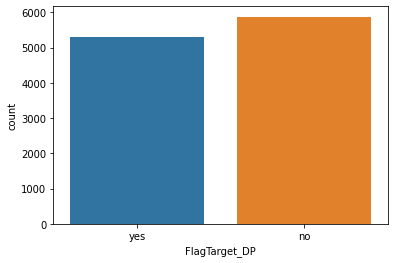

In [47]:
#NO VA TESIS
sns.countplot(x='FlagTarget_DP',data=bank_dp)
plt.show()

no     5873
yes    5289
Name: FlagTarget_DP, dtype: int64

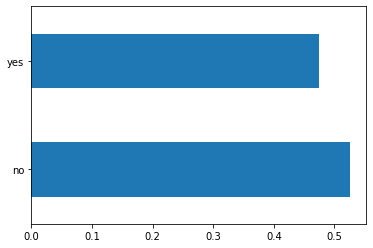

In [48]:
bank_dp.FlagTarget_DP.value_counts(normalize=True).plot.barh();
bank_dp.FlagTarget_DP.value_counts()

**Conclusiones**:

- El dataset proporcionado está balanceado para la variable objetivo `FlagTarget_DP`, la diferencia entre los "yes" y "no" no es muy grande, por lo tanto los modelos de machine learning a comparar pueden ser fiables en su predicción.

In [49]:
#EXPORT PARQUET
path="../output/"
bank_dp.to_parquet(path+"data-bank_1.parquet",engine="pyarrow")